# Threshold sensitivity: exchange-rate application

Refits the four models of `Exchange_rate_application.ipynb` (likelihood GPDFlow,
two-stage MMD GPDFlow, probit-copula RealNVP, parametric mGPD) on the same
GARCH-filtered FX residuals at threshold levels $q \in \{0.95, 0.96, 0.97, 0.975\}$.

**Hyperparameters are tuned per model and per threshold** by `tune_threshold_hparams.py`
(run it before this notebook): a coordinate-wise grid search over the Table 2 search
spaces with 5-fold CV, where a configuration is scored by the RMSE between the
fold-mean of the five out-of-fold $\chi(0.98)$ matrices and the empirical $\chi(0.98)$.
Hidden widths are searched as multiples of the dimension (`latent_size_factor`,
`hidden_mult` $\in \{2, 3, 4\}$), the factors behind Table 2's widths.
The parametric mGPD generator family is selected the same way at every threshold.
The selected settings (and the median of their per-fold early-stop epochs) are read
from `RES_DIR/best_configs.json`; this notebook does no CV.

For every model and threshold, **one** model is fitted on the full exceedance slice with
the selected configuration, stopped at that median CV epoch.  The final model is
scored by the RMSE of pairwise $\chi(0.98)$ and $\omega(0.98)$ against the empirical
values on the full data.  The evaluation level $0.98$ is held **fixed** across thresholds,
so the RMSEs are directly comparable; model draws (cluster-conditional) are re-levelled to
$q_{clus} = 1 - (1 - 0.98)/p_{cluster}$.

The two-stage MMD final fit uses `cv_utils.fit_full_gpdflow_mmd`, whose Stage-1 GPD fit
clips $\gamma$ to $\pm 0.5$ (as in the CV folds).

In [ ]:
import os
import json
import glob
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

import Common_Functions as cf
import parametric_mGPD
importlib.reload(parametric_mGPD)
import cv_utils
importlib.reload(cv_utils)
from cv_utils import (
    fit_full_gpdflow_likelihood,
    fit_full_gpdflow_mmd,
    fit_full_flow_baseline,
    fit_full_parametric_mgpd,
)

SMOKE = False                     # set True for a fast top-to-bottom check
EPOCHS_LIK = 5 if SMOKE else 500
EPOCHS_MMD = 5 if SMOKE else 500
EPOCHS_BL  = 5 if SMOKE else 500
EPOCHS_PAR = 5 if SMOKE else 500
N_SIM_FINAL = 200_000             # rows drawn from each final full-data model

Q_LIST = [0.95, 0.96, 0.97, 0.975]   # threshold levels under study
Q_EVAL = 0.98                        # fixed level of the chi / omega evaluation

dir_out = "/home/pgrad2/2448355h/My_PhD_Project/GPDFlow/Data_and_Model/"
RES_DIR = dir_out + ("threshold_sensitivity_smoke/" if SMOKE else "threshold_sensitivity/")
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(dir_out + 'Plots/', exist_ok=True)

# --- Non-tuned settings (as in Exchange_rate_application.ipynb) -------------
# The tuned hyperparameters (num_layers, latent_size_factor / hidden_mult,
# marg_lambda, mmd_indicator_alpha / rho, generator) come from best_configs.json,
# written by tune_threshold_hparams.py (5-fold CV, criterion RMSE of chi(0.98)).
BASE_CFG = {
    'lik': dict(penalty_lambda=1e4, seed=1234),
    'mmd': dict(warmup_epochs=50, min_delta=1e-3,
                penalty_lambda=1e4, mmd_lambda=15, mmd_samples_per_face=128,
                mmd_censor_c=0, mmd_censor_tau=0.2, seed=1234),
    'bl': dict(warmup=20, seed=0),
    'par': dict(seed=1234),
}
with open(RES_DIR + 'best_configs.json') as f:
    BEST = json.load(f)
for q in Q_LIST:
    for m in ['lik', 'mmd', 'bl', 'par']:
        assert m in BEST.get(str(q), {}), f'no tuned config for q={q}, model={m}'

MODELS = ['lik', 'mmd', 'bl', 'par']
MODEL_NAMES = {'lik': 'GPDFlow (Likelihood)', 'mmd': 'GPDFlow (MMD)',
               'bl': 'Probit-transformed RealNVP', 'par': 'Parametric mGPD'}
MODEL_COLORS = {'lik': 'darkgoldenrod', 'mmd': 'firebrick',
                'bl': 'steelblue', 'par': 'seagreen'}

## Data: GARCH-filtered absolute residuals of daily GBP exchange rates

Same pipeline as `Exchange_rate_application.ipynb`: negative log returns of the Bank of England series, ARMA(0,2)+GARCH(1,1) per column via R's `fGarch::garchFit`, absolute standardized residuals.  The result is cached in `RES_DIR` so later runs skip the R step.

In [2]:
_origin_cache = RES_DIR + 'samples_origin.npy'

if os.path.exists(_origin_cache):
    samples_origin = np.load(_origin_cache)
    print('loaded cached residuals:', _origin_cache)
else:
    import rpy2.robjects as ro
    from rpy2.robjects import numpy2ri, default_converter
    from rpy2.robjects.conversion import localconverter
    from rpy2.robjects.packages import importr

    BoE_exchange_rates = pd.read_csv(
        "Data_and_Model/BoE_exchange_rates.csv", index_col="Date", parse_dates=True
    )
    nlr = pd.DataFrame(
        np.diff(np.log(BoE_exchange_rates.values), axis=0),
        columns=BoE_exchange_rates.columns,
        index=BoE_exchange_rates.index[1:],
    )

    fGarch = importr("fGarch")
    garch_formula = ro.Formula("~arma(0,2)+garch(1,1)")
    residus = pd.DataFrame(np.nan, index=nlr.index, columns=nlr.columns)
    for i, col in enumerate(nlr.columns):
        obs = nlr[col].dropna()
        with localconverter(default_converter + numpy2ri.converter):
            r_x = ro.conversion.py2rpy(obs.to_numpy())
            ga = fGarch.garchFit(garch_formula, data=r_x, trace=False, **{"cond.dist": "norm"})
        resid = np.asarray(ga.slots["residuals"])
        sigma_t = np.asarray(ga.slots["sigma.t"])
        residus.loc[obs.index, col] = resid / sigma_t
        print(f"Done for {i + 1}/{nlr.shape[1]}")

    samples_origin = residus.abs().values
    np.save(_origin_cache, samples_origin)

n_obs, dim = samples_origin.shape
iu = np.triu_indices(dim, k=1)
print('samples_origin:', samples_origin.shape, '| NaNs:', int(np.isnan(samples_origin).sum()))

# Empirical references at the fixed evaluation level (shared by every threshold).
chi_emp = cf.pairwise_chi_from_data(samples_origin, p=Q_EVAL)
omega_emp = cf.pairwise_omega_from_data(samples_origin, p=Q_EVAL)

Done for 1/22
Done for 2/22
Done for 3/22
Done for 4/22
Done for 5/22
Done for 6/22
Done for 7/22
Done for 8/22
Done for 9/22
Done for 10/22
Done for 11/22
Done for 12/22
Done for 13/22
Done for 14/22
Done for 15/22
Done for 16/22
Done for 17/22
Done for 18/22
Done for 19/22
Done for 20/22
Done for 21/22
Done for 22/22
samples_origin: (5051, 22) | NaNs: 0


## Helpers: fit all four models at one threshold (tuned settings), and plot

In [ ]:
def _free(*objs):
    for o in objs:
        del o
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def run_threshold(q):
    '''Full-data fit of the four models at threshold level q, each with its
    CV-selected configuration (best_configs.json) and stopped at the median of
    that configuration's per-fold CV early-stop epochs.

    Returns (and saves to RES_DIR/q{q}.npz) the chi / omega matrices at Q_EVAL of
    each final model, their RMSEs against the empirical values, the selected
    configuration, its CV RMSE_chi and stop epoch, and the slice size / p_cluster.
    '''
    thres = np.quantile(samples_origin, q, axis=0)
    cond = np.any(samples_origin > thres, axis=1)
    samples = samples_origin[cond, :] - thres.reshape(1, -1)
    p_cluster = samples.shape[0] / n_obs
    q_clus = 1.0 - (1.0 - Q_EVAL) / p_cluster      # cluster-conditional level matching Q_EVAL
    print(f'q = {q}: slice {samples.shape}, p_cluster = {p_cluster:.4f}, q_clus = {q_clus:.4f}')
    assert 0.0 < q_clus < 1.0, q_clus

    full_fitters = {
        'lik': lambda cfg, e: fit_full_gpdflow_likelihood(
            samples, device, thres, n_eval=N_SIM_FINAL, epochs=EPOCHS_LIK,
            stop_at_epoch=e, **cfg),
        'mmd': lambda cfg, e: fit_full_gpdflow_mmd(
            samples, device, thres, n_eval=N_SIM_FINAL, epochs=EPOCHS_MMD,
            stop_at_epoch=e, **cfg),
        'bl': lambda cfg, e: fit_full_flow_baseline(
            samples, device, thres, n_eval=N_SIM_FINAL, epochs=EPOCHS_BL,
            stop_at_epoch=e, **cfg),
        'par': lambda cfg, e: fit_full_parametric_mgpd(
            samples, device, thres, cfg.pop('generator'), n_eval=N_SIM_FINAL,
            epochs=EPOCHS_PAR, stop_at_epoch=e, **cfg),
    }

    out = {'q': q, 'n_slice': samples.shape[0], 'p_cluster': p_cluster, 'q_clus': q_clus}
    for m in MODELS:
        best = BEST[str(q)][m]
        med = max(int(best['median_epoch']), 1)
        cfg = {**BASE_CFG[m], **best['cfg']}
        print(f'\n=== {MODEL_NAMES[m]}: full-data fit (q = {q}), {best["cfg"]}, '
              f'stop_at_epoch = {med} ===')
        model, draws, _ = full_fitters[m](dict(cfg), med)
        draws = draws[np.isfinite(draws).all(axis=1)]
        chi_hat = cf.pairwise_chi_from_data(draws, p=q_clus)
        omega_hat = cf.pairwise_omega_from_data(draws, p=q_clus)
        out[f'{m}_cfg'] = json.dumps(best['cfg'])
        out[f'{m}_cv_rmse_chi'] = float(best['cv_rmse_chi'])
        out[f'{m}_fold_epochs'] = np.array(best['fold_epochs'])
        out[f'{m}_median_epoch'] = med
        out[f'{m}_n_draws'] = draws.shape[0]
        out[f'{m}_chi'] = chi_hat
        out[f'{m}_omega'] = omega_hat
        out[f'{m}_rmse_chi'] = cf.rmse_chi(chi_hat[iu], chi_emp[iu])
        out[f'{m}_rmse_omega'] = cf.rmse_chi(omega_hat[iu], omega_emp[iu])
        print(f'{MODEL_NAMES[m]}:  RMSE_chi = {out[f"{m}_rmse_chi"]:.4f}   '
              f'RMSE_omega = {out[f"{m}_rmse_omega"]:.4f}   '
              f'(CV RMSE_chi = {out[f"{m}_cv_rmse_chi"]:.4f})')
        _free(model, draws)

    np.savez(RES_DIR + f'q{q}.npz', **out)
    return out


def plot_scatter_1x4(res_q, measure):
    '''1x4 scatter of empirical vs model pairwise chi / omega at Q_EVAL, one panel per model.'''
    sym = r'\chi' if measure == 'chi' else r'\omega'
    emp = (chi_emp if measure == 'chi' else omega_emp)[iu]
    q = float(res_q['q'])
    hats = {m: np.asarray(res_q[f'{m}_{measure}'])[iu] for m in MODELS}
    lo = min(emp.min(), *(h.min() for h in hats.values()))
    hi = max(emp.max(), *(h.max() for h in hats.values()))
    pad = 0.05 * (hi - lo)
    lims = [lo - pad, hi + pad]

    sns.set(style="ticks", font_scale=1.3)
    fig, axes = plt.subplots(1, 4, figsize=(24, 6.5), sharex=True, sharey=True)
    for ax, m in zip(axes, MODELS):
        ax.scatter(emp, hats[m], color=MODEL_COLORS[m], alpha=0.7, s=30)
        ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
        ax.set_xlim(lims); ax.set_ylim(lims)
        name = MODEL_NAMES[m]
        if m == 'par':
            name += f" ({json.loads(str(res_q['par_cfg'])).get('generator')})"
        ax.set_title(f'{name}\n'
                     rf'$RMSE_{sym}$ = {float(res_q[f"{m}_rmse_{measure}"]):.4f}',
                     color='black', fontsize=16)
        ax.set_xlabel(rf'Empirical ${sym}_{{ij}}({Q_EVAL})$', color='black')
        ax.tick_params(axis='both', labelcolor='black')
    axes[0].set_ylabel(rf'Model $\hat{{{sym}}}_{{ij}}({Q_EVAL})$', color='black')
    fig.suptitle(f'Threshold q = {q}', color='black', fontsize=18)
    fig.tight_layout()
    fig.savefig(dir_out + f'Plots/thr_sens_{measure}_q{q}.pdf', bbox_inches='tight')
    plt.show()

    print(f'RMSE_{measure} at {Q_EVAL}, threshold q = {q}:')
    for m in MODELS:
        print(f'  {MODEL_NAMES[m]:30s} {float(res_q[f"{m}_rmse_{measure}"]):.4f}')


res = {}

## Threshold q = 0.95

In [4]:
res[0.95] = run_threshold(0.95)

q = 0.95: slice (1918, 22), p_cluster = 0.3797, q_clus = 0.9473

=== GPDFlow (Likelihood): 5-fold CV (q = 0.95) ===
[likelihood] fold 1/5 (train 1534, val 384)
  scipy margin init  gamma~[0.194 0.235 0.173 0.164 0.109 0.181 0.171 0.125 0.101 0.18  0.107 0.114
 0.113 0.178 0.128 0.222 0.104 0.091 0.379 0.131 0.244 0.259]
  scipy margin init  sigma~[0.527 0.435 0.452 0.517 0.529 0.466 0.417 0.517 0.576 0.557 0.539 0.554
 0.533 0.482 0.535 0.403 0.49  0.522 0.448 0.525 0.465 0.567]
  epoch    1/500 | train=212.6133 | val=199.1830 | val_nll=33.5983
  epoch   25/500 | train=167.4779 | val=159.3207 | val_nll=25.3571
  epoch   50/500 | train=161.0979 | val=157.8719 | val_nll=22.1325
  epoch   75/500 | train=161.8579 | val=157.1302 | val_nll=20.8692
  epoch  100/500 | train=160.9165 | val=157.8480 | val_nll=21.4973
  epoch  125/500 | train=157.3464 | val=158.2822 | val_nll=22.1348
  epoch  150/500 | train=158.7131 | val=159.5491 | val_nll=23.0807
  epoch  175/500 | train=158.2529 | val=161.583

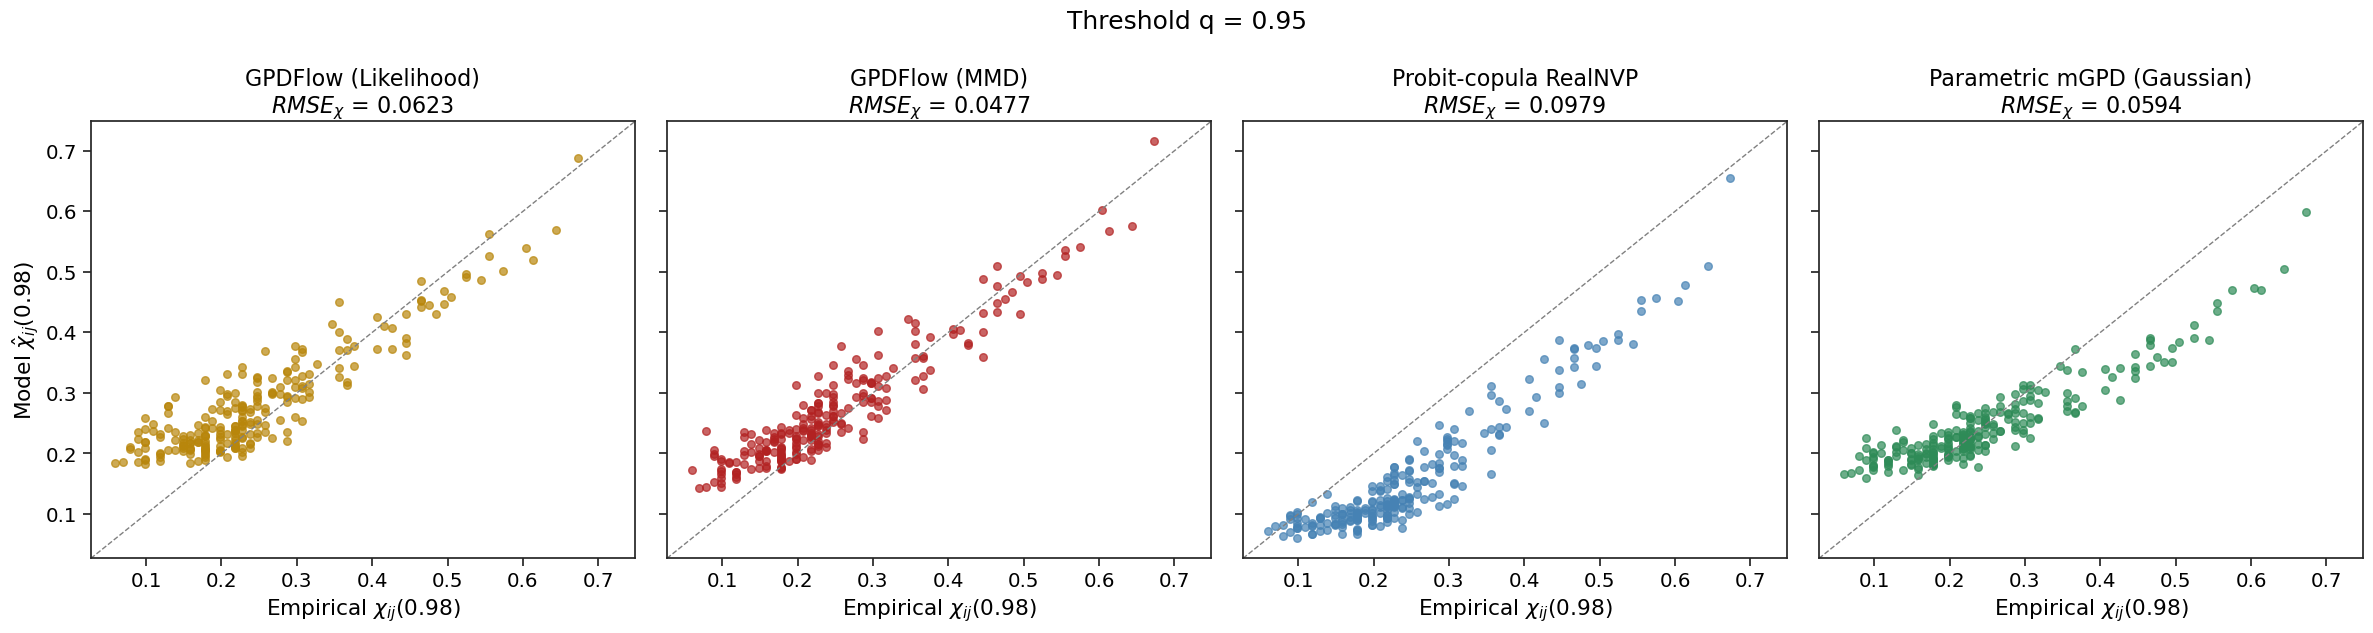

RMSE_chi at 0.98, threshold q = 0.95:
  GPDFlow (Likelihood)           0.0623
  GPDFlow (MMD)                  0.0477
  Probit-copula RealNVP          0.0979
  Parametric mGPD (Gaussian)     0.0594


In [5]:
plot_scatter_1x4(res[0.95], 'chi')

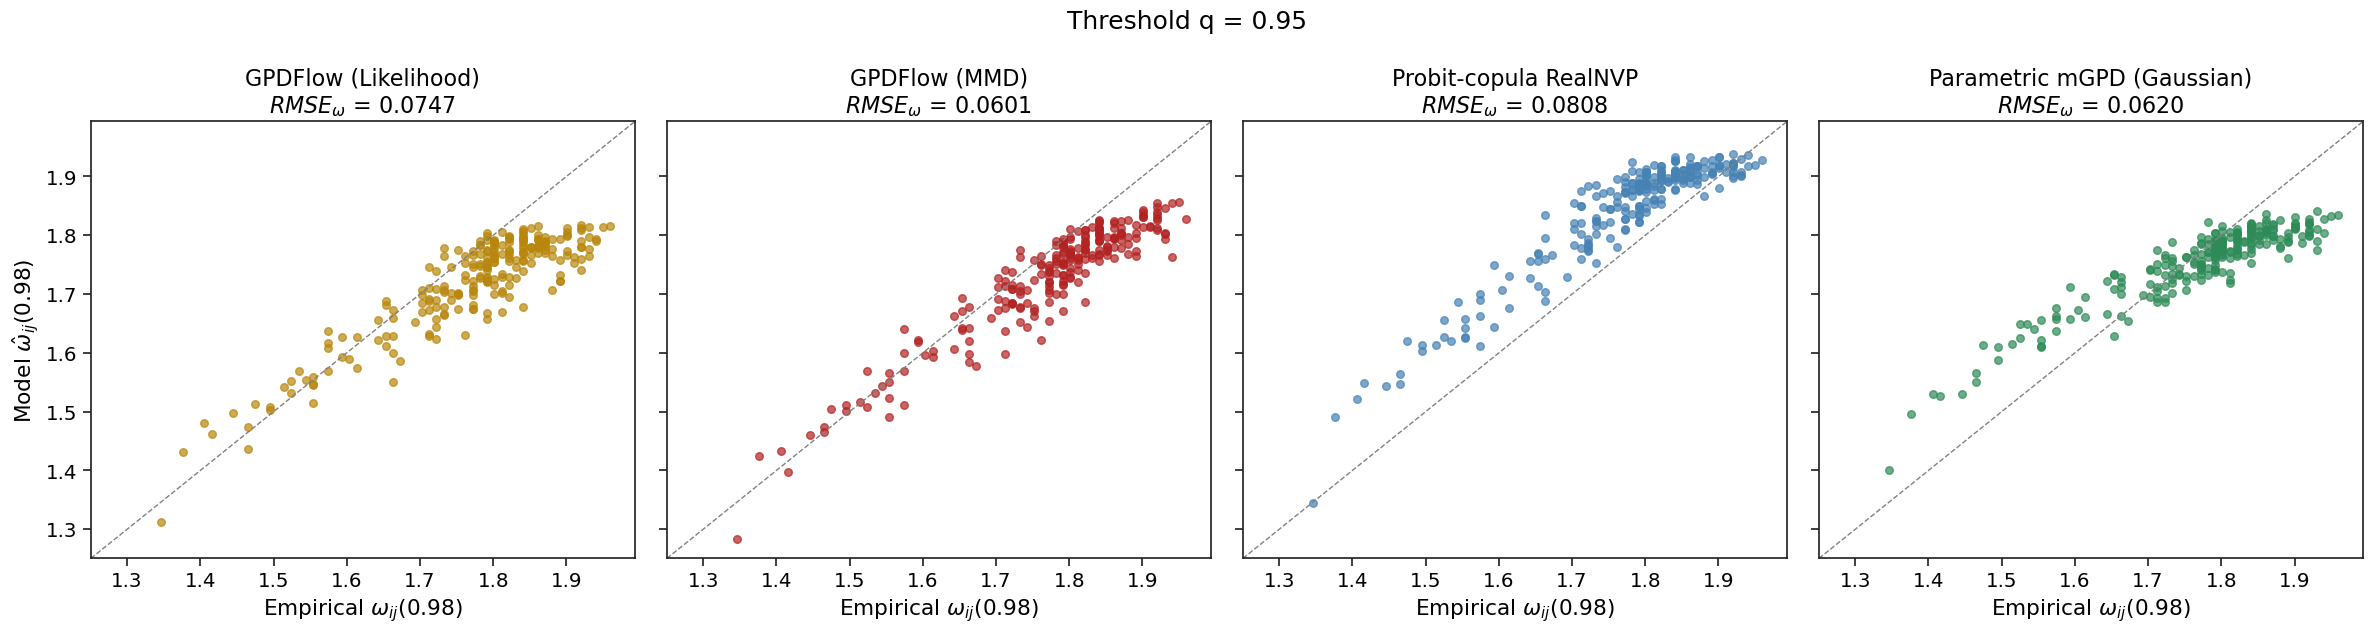

RMSE_omega at 0.98, threshold q = 0.95:
  GPDFlow (Likelihood)           0.0747
  GPDFlow (MMD)                  0.0601
  Probit-copula RealNVP          0.0808
  Parametric mGPD (Gaussian)     0.0620


In [6]:
plot_scatter_1x4(res[0.95], 'omega')

## Threshold q = 0.96

In [7]:
res[0.96] = run_threshold(0.96)

q = 0.96: slice (1609, 22), p_cluster = 0.3186, q_clus = 0.9372

=== GPDFlow (Likelihood): 5-fold CV (q = 0.96) ===
[likelihood] fold 1/5 (train 1287, val 322)
  scipy margin init  gamma~[0.255 0.231 0.148 0.206 0.19  0.102 0.166 0.142 0.114 0.199 0.1   0.154
 0.112 0.12  0.151 0.21  0.123 0.124 0.361 0.157 0.236 0.264]
  scipy margin init  sigma~[0.504 0.447 0.489 0.524 0.487 0.574 0.485 0.505 0.595 0.573 0.548 0.527
 0.514 0.555 0.525 0.457 0.468 0.505 0.51  0.498 0.507 0.605]
  epoch    1/500 | train=227.0549 | val=193.2987 | val_nll=33.8946
  epoch   25/500 | train=182.7001 | val=152.2302 | val_nll=26.1783
  epoch   50/500 | train=177.7937 | val=149.1349 | val_nll=22.2966
  epoch   75/500 | train=175.0896 | val=149.3935 | val_nll=21.1880
  epoch  100/500 | train=174.3185 | val=149.4957 | val_nll=21.3595
  epoch  125/500 | train=175.8863 | val=149.1895 | val_nll=21.0632
  epoch  150/500 | train=170.2571 | val=149.5941 | val_nll=21.9391
  epoch  175/500 | train=173.3004 | val=150.818

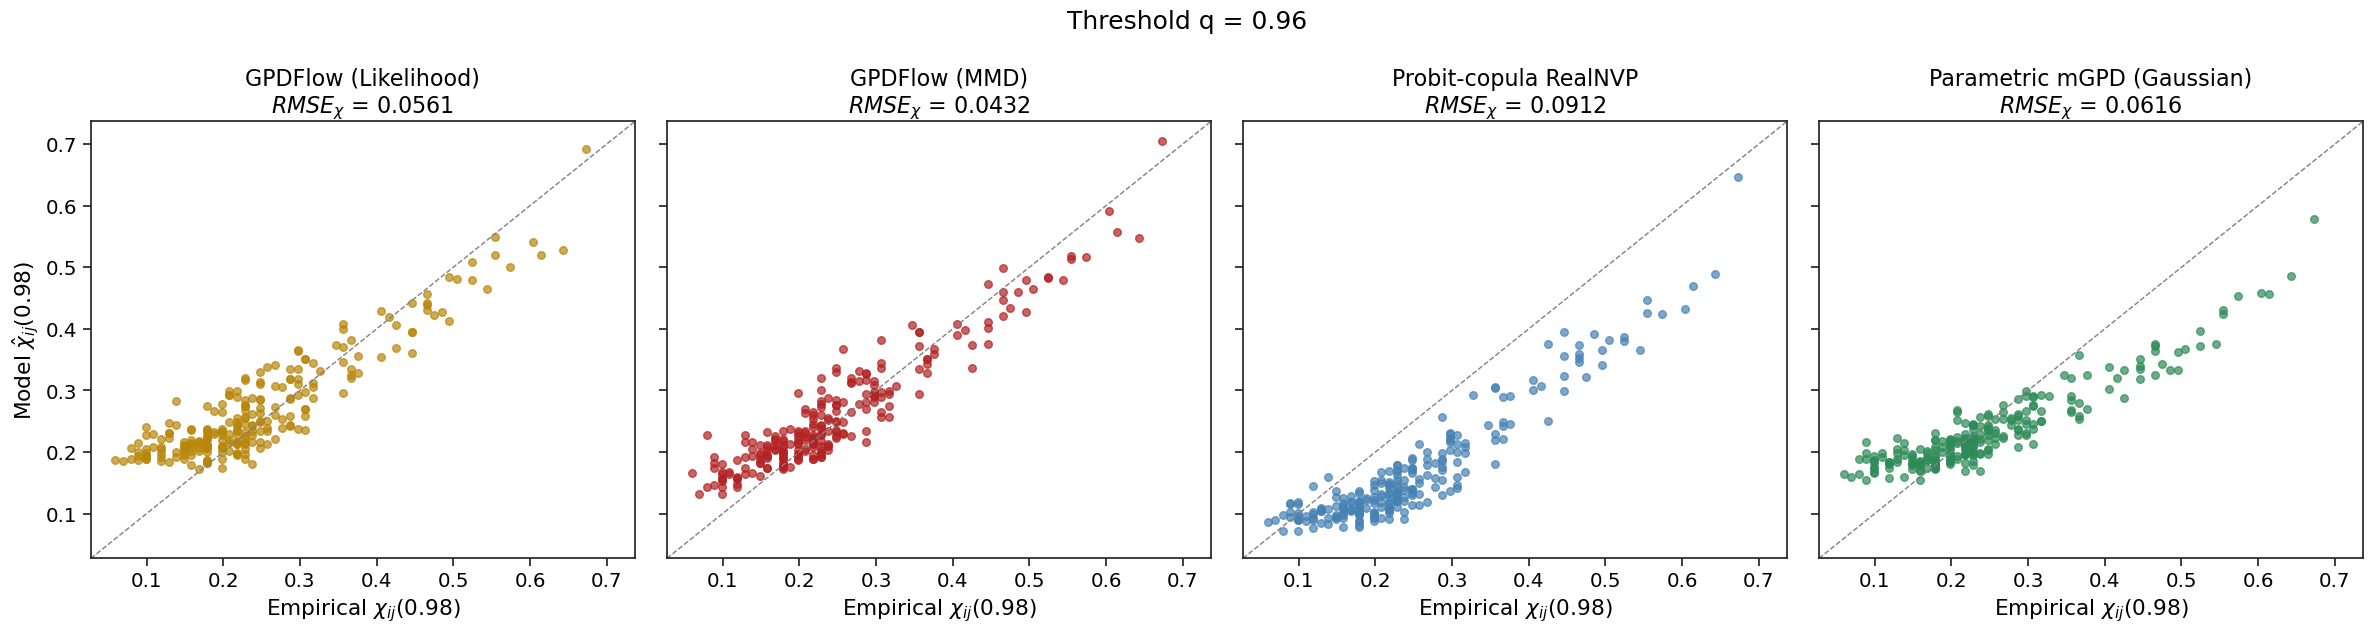

RMSE_chi at 0.98, threshold q = 0.96:
  GPDFlow (Likelihood)           0.0561
  GPDFlow (MMD)                  0.0432
  Probit-copula RealNVP          0.0912
  Parametric mGPD (Gaussian)     0.0616


In [8]:
plot_scatter_1x4(res[0.96], 'chi')

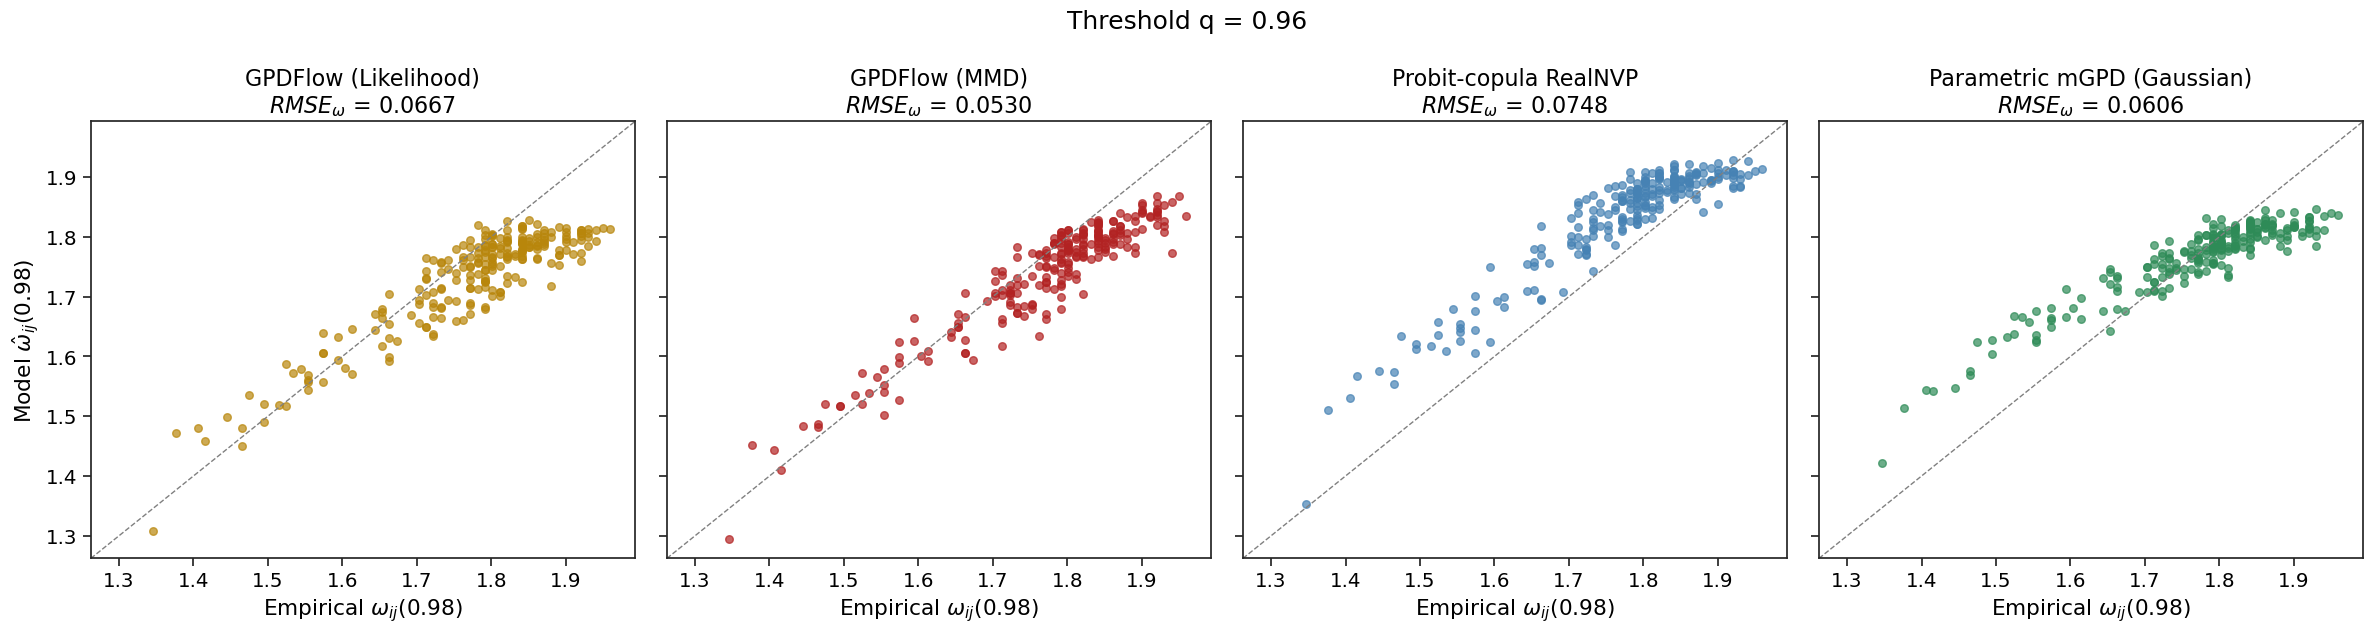

RMSE_omega at 0.98, threshold q = 0.96:
  GPDFlow (Likelihood)           0.0667
  GPDFlow (MMD)                  0.0530
  Probit-copula RealNVP          0.0748
  Parametric mGPD (Gaussian)     0.0606


In [9]:
plot_scatter_1x4(res[0.96], 'omega')

## Threshold q = 0.97

In [10]:
res[0.97] = run_threshold(0.97)

q = 0.97: slice (1288, 22), p_cluster = 0.2550, q_clus = 0.9216

=== GPDFlow (Likelihood): 5-fold CV (q = 0.97) ===
[likelihood] fold 1/5 (train 1030, val 258)
  scipy margin init  gamma~[0.271 0.244 0.212 0.173 0.182 0.183 0.176 0.115 0.18  0.242 0.17  0.178
 0.297 0.127 0.114 0.416 0.236 0.063 0.182 0.147 0.26  0.227]
  scipy margin init  sigma~[0.536 0.453 0.445 0.602 0.497 0.499 0.479 0.534 0.526 0.555 0.505 0.554
 0.409 0.516 0.575 0.332 0.37  0.588 0.52  0.515 0.5   0.65 ]
  epoch    1/500 | train=222.8110 | val=220.4522 | val_nll=36.2221
  epoch   25/500 | train=182.1698 | val=174.6075 | val_nll=29.1091
  epoch   50/500 | train=175.4206 | val=167.9393 | val_nll=25.4055
  epoch   75/500 | train=173.0621 | val=170.4469 | val_nll=24.7408
  epoch  100/500 | train=171.7643 | val=168.4878 | val_nll=24.4671
  epoch  125/500 | train=169.0795 | val=167.8456 | val_nll=24.1567
  epoch  150/500 | train=174.9725 | val=167.0980 | val_nll=24.0655
  epoch  175/500 | train=168.5476 | val=168.186

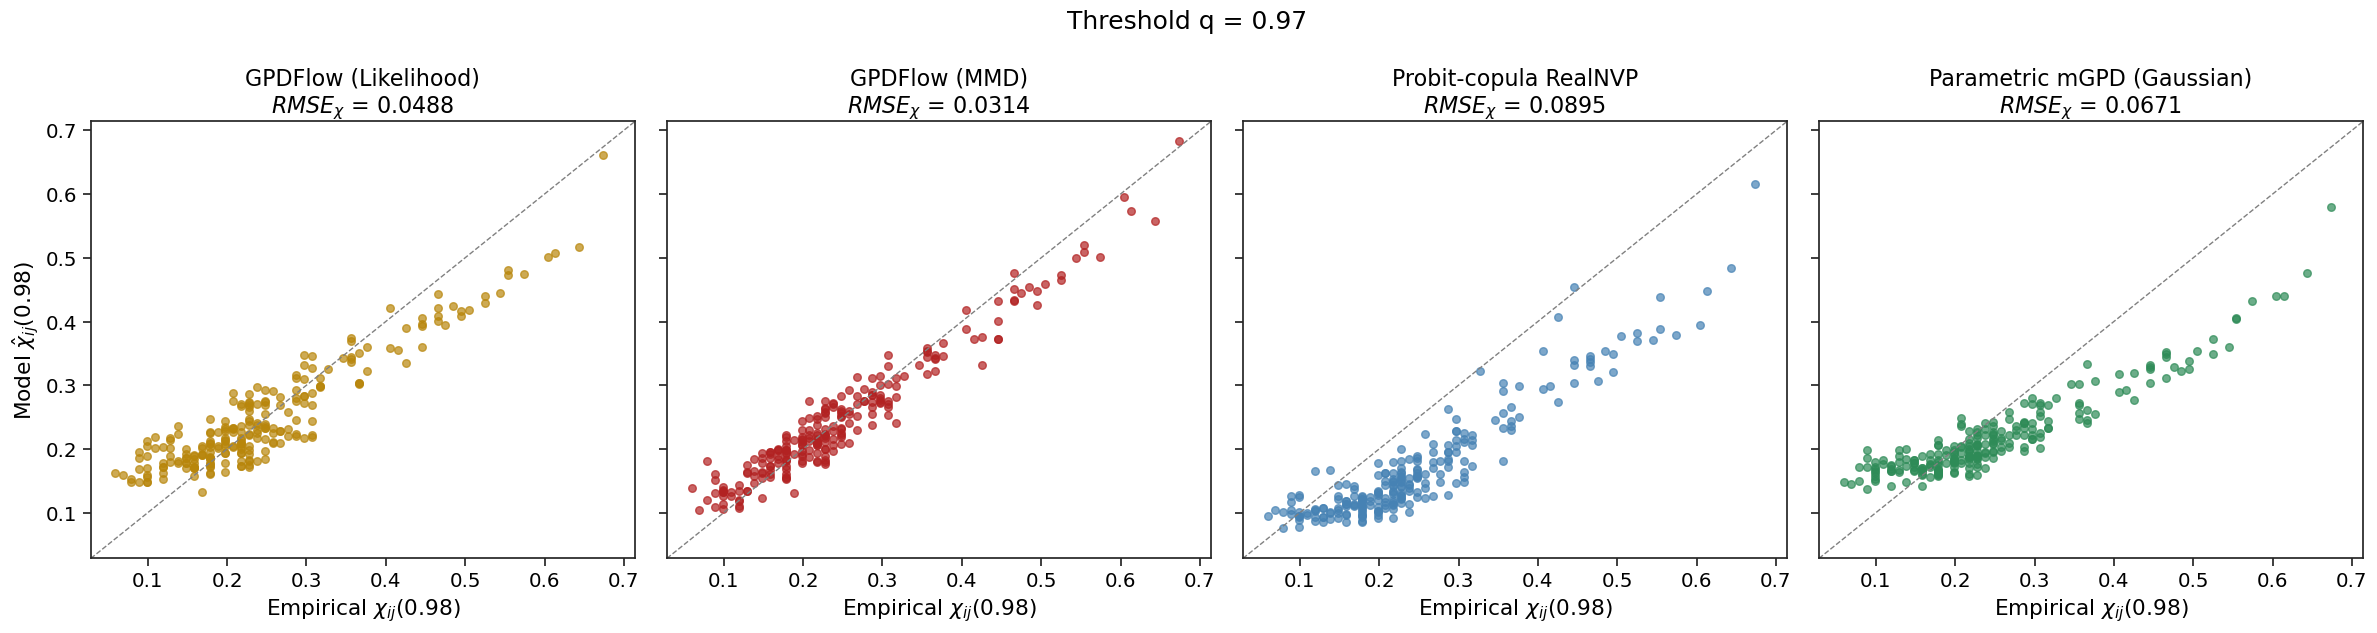

RMSE_chi at 0.98, threshold q = 0.97:
  GPDFlow (Likelihood)           0.0488
  GPDFlow (MMD)                  0.0314
  Probit-copula RealNVP          0.0895
  Parametric mGPD (Gaussian)     0.0671


In [11]:
plot_scatter_1x4(res[0.97], 'chi')

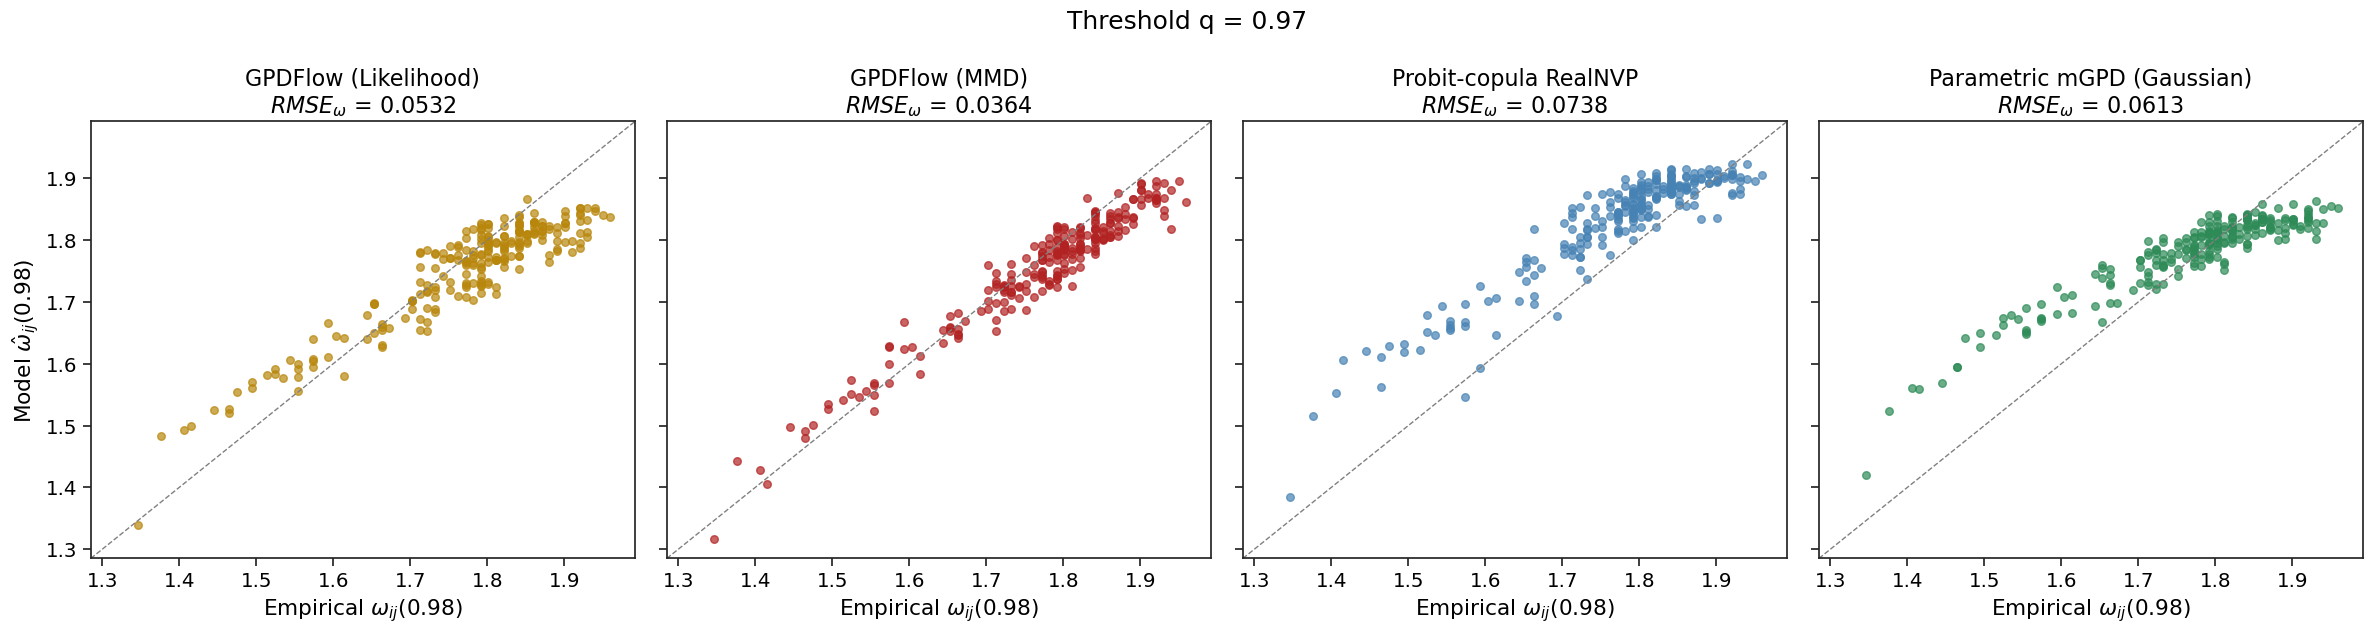

RMSE_omega at 0.98, threshold q = 0.97:
  GPDFlow (Likelihood)           0.0532
  GPDFlow (MMD)                  0.0364
  Probit-copula RealNVP          0.0738
  Parametric mGPD (Gaussian)     0.0613


In [12]:
plot_scatter_1x4(res[0.97], 'omega')

## Threshold q = 0.975

In [13]:
res[0.975] = run_threshold(0.975)

q = 0.975: slice (1105, 22), p_cluster = 0.2188, q_clus = 0.9086

=== GPDFlow (Likelihood): 5-fold CV (q = 0.975) ===
[likelihood] fold 1/5 (train 884, val 221)
  scipy margin init  gamma~[0.343 0.246 0.188 0.217 0.214 0.237 0.139 0.221 0.169 0.19  0.197 0.225
 0.291 0.083 0.136 0.271 0.317 0.145 0.166 0.157 0.137 0.279]
  scipy margin init  sigma~[0.452 0.466 0.508 0.592 0.485 0.46  0.569 0.421 0.552 0.654 0.496 0.497
 0.413 0.573 0.565 0.449 0.343 0.519 0.549 0.531 0.55  0.684]
  epoch    1/500 | train=230.8170 | val=229.4850 | val_nll=38.4186
  epoch   25/500 | train=183.3936 | val=170.0396 | val_nll=31.4022
  epoch   50/500 | train=181.4435 | val=158.0351 | val_nll=26.6341
  epoch   75/500 | train=178.6802 | val=155.5594 | val_nll=25.1735
  epoch  100/500 | train=178.5012 | val=155.4768 | val_nll=24.7304
  epoch  125/500 | train=179.0130 | val=156.7510 | val_nll=26.7638
  epoch  150/500 | train=175.3246 | val=158.2276 | val_nll=27.8164
  early stopping at epoch 159 (best val NLL @ 

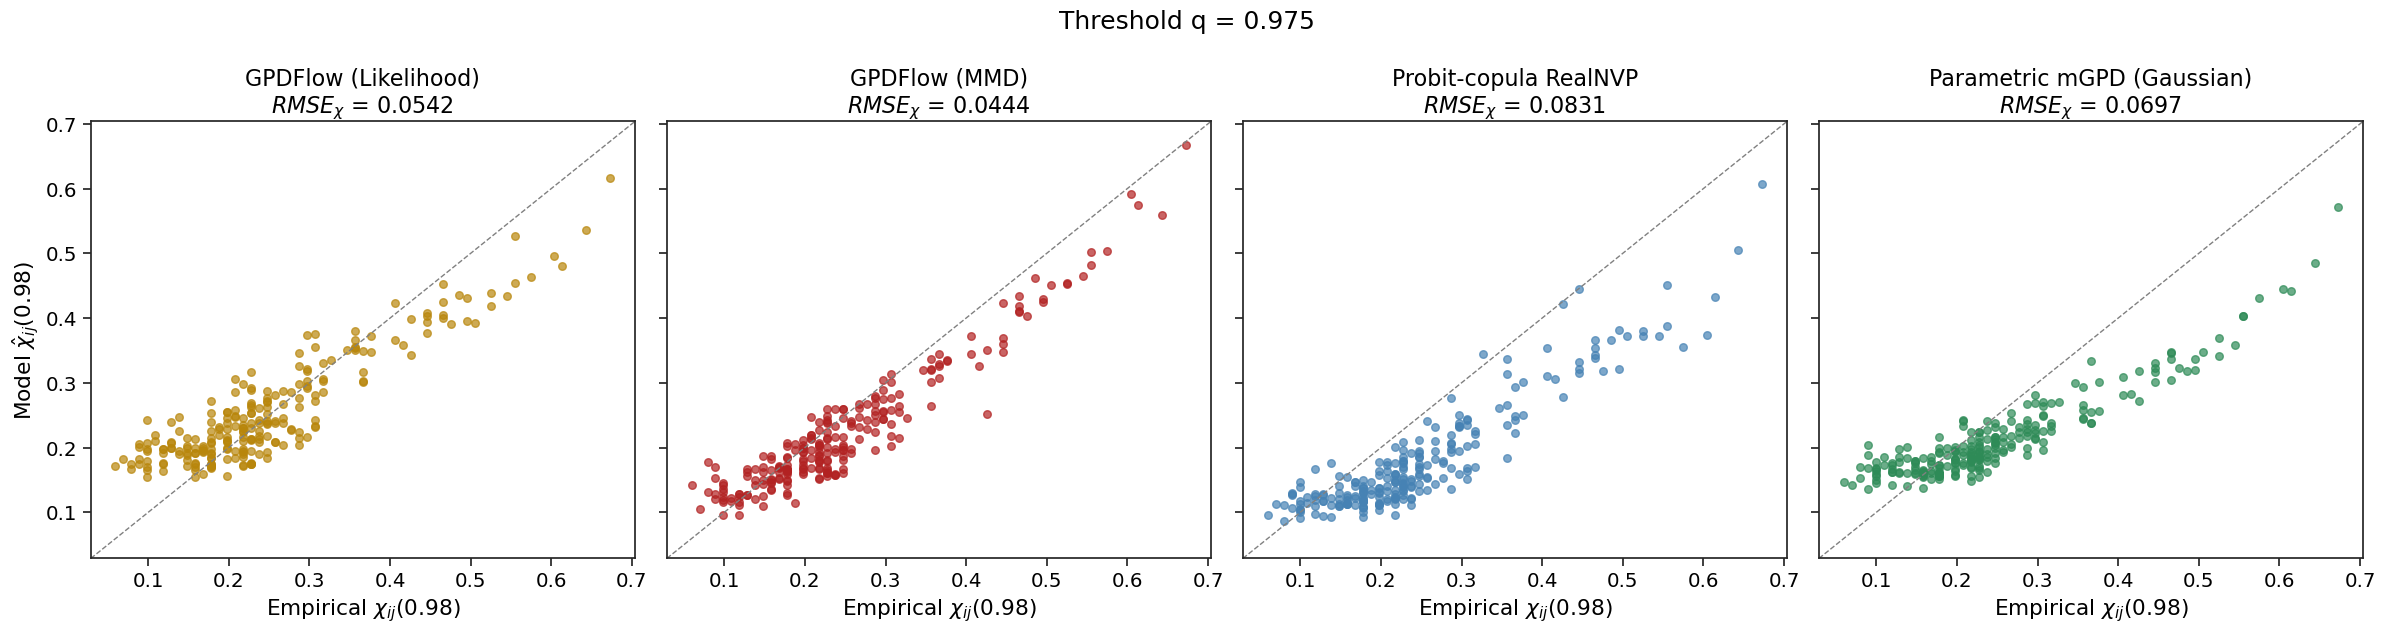

RMSE_chi at 0.98, threshold q = 0.975:
  GPDFlow (Likelihood)           0.0542
  GPDFlow (MMD)                  0.0444
  Probit-copula RealNVP          0.0831
  Parametric mGPD (Gaussian)     0.0697


In [14]:
plot_scatter_1x4(res[0.975], 'chi')

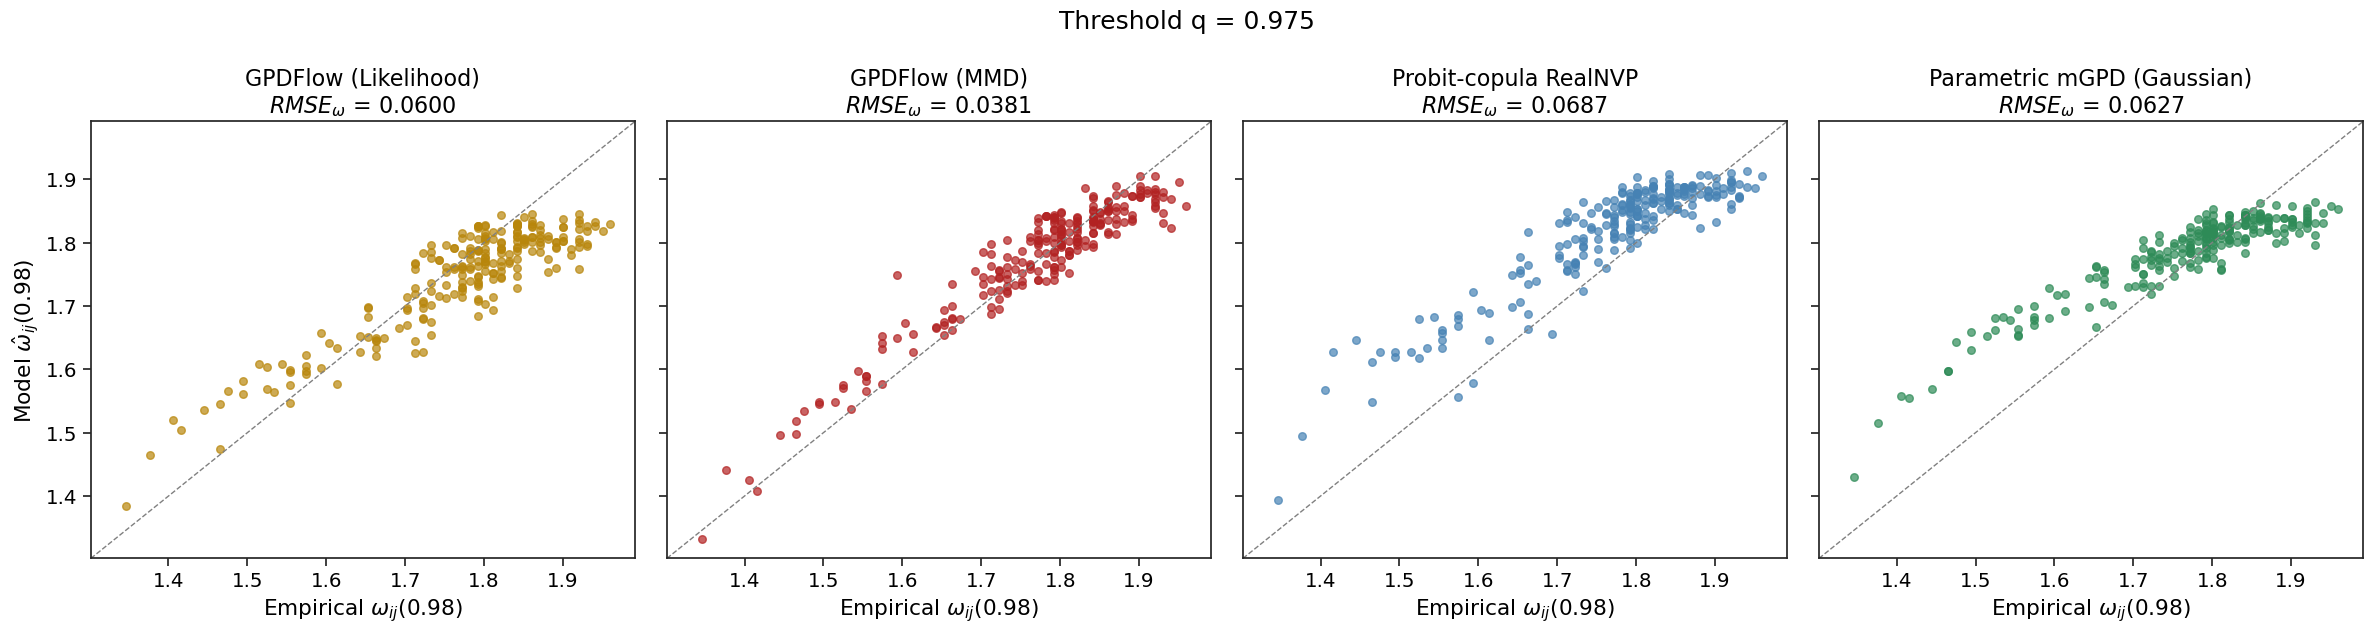

RMSE_omega at 0.98, threshold q = 0.975:
  GPDFlow (Likelihood)           0.0600
  GPDFlow (MMD)                  0.0381
  Probit-copula RealNVP          0.0687
  Parametric mGPD (Gaussian)     0.0627


In [15]:
plot_scatter_1x4(res[0.975], 'omega')

## Summary across thresholds

Reloads the per-threshold results from `RES_DIR`, so this section runs on its own after a kernel restart without refitting.

In [ ]:
res_all = {}
for q in Q_LIST:
    f = RES_DIR + f'q{q}.npz'
    if os.path.exists(f):
        res_all[q] = dict(np.load(f))
    else:
        print('missing:', f)
q_done = sorted(res_all)

slice_table = pd.DataFrame(
    {q: {'n_slice': int(res_all[q]['n_slice']),
         'p_cluster': float(res_all[q]['p_cluster']),
         'q_clus': float(res_all[q]['q_clus'])} for q in q_done})
cfg_table = pd.DataFrame(
    {q: {MODEL_NAMES[m]: ', '.join(f'{k}={v}' for k, v in
                                   json.loads(str(res_all[q][f'{m}_cfg'])).items())
         for m in MODELS} for q in q_done})
cv_rmse_table = pd.DataFrame(
    {q: {MODEL_NAMES[m]: float(res_all[q][f'{m}_cv_rmse_chi']) for m in MODELS}
     for q in q_done})
median_epoch_table = pd.DataFrame(
    {q: {MODEL_NAMES[m]: int(res_all[q][f'{m}_median_epoch']) for m in MODELS} for q in q_done})
rmse_tables = {
    meas: pd.DataFrame({q: {MODEL_NAMES[m]: float(res_all[q][f'{m}_rmse_{meas}'])
                            for m in MODELS} for q in q_done})
    for meas in ['chi', 'omega']
}
for t in [slice_table, cfg_table, cv_rmse_table, median_epoch_table, *rmse_tables.values()]:
    t.columns.name = 'threshold q'

print('Exceedance slice per threshold:\n', slice_table.round(4).to_string(), '\n')
with pd.option_context('display.max_colwidth', None):
    print('Selected hyperparameters (5-fold CV, RMSE of chi(0.98)):\n', cfg_table.to_string(), '\n')
print(f'CV RMSE_chi at {Q_EVAL} of the selected configuration:\n',
      cv_rmse_table.round(4).to_string(), '\n')
cfg_table.to_csv(RES_DIR + 'selected_hparams_by_threshold.csv')
print('Median CV early-stop epoch (stop_at_epoch of the full-data fit):\n',
      median_epoch_table.to_string(), '\n')
for meas, t in rmse_tables.items():
    print(f'RMSE_{meas} at {Q_EVAL}:\n', t.round(4).to_string(), '\n')
    t.to_csv(RES_DIR + f'rmse_{meas}_by_threshold.csv')

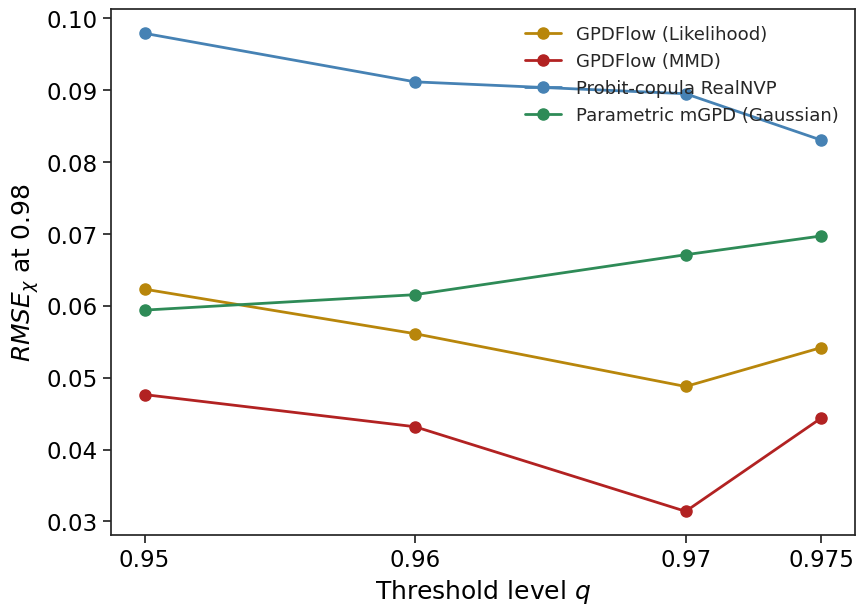

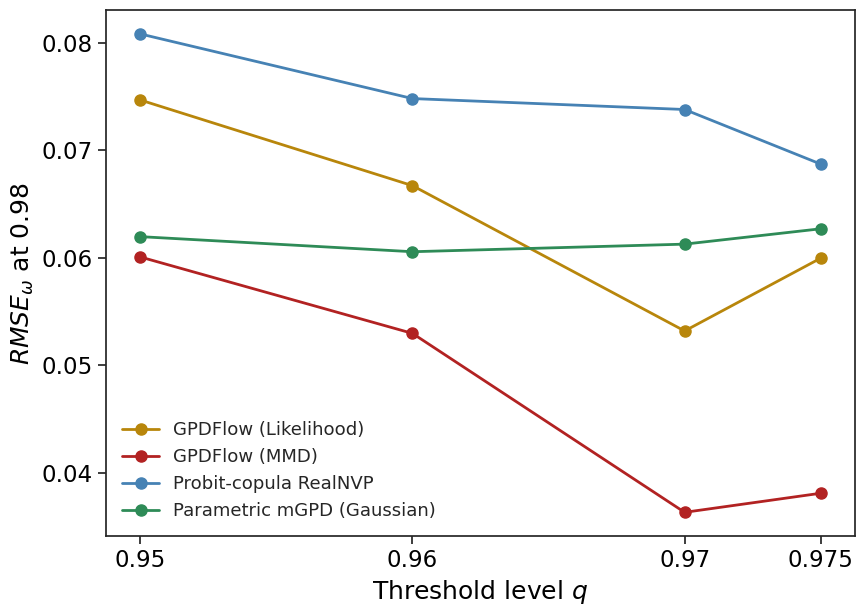

In [17]:
for meas, sym in [('chi', r'\chi'), ('omega', r'\omega')]:
    sns.set(style="ticks", font_scale=1.5)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for m in MODELS:
        ax.plot(q_done, [float(res_all[q][f'{m}_rmse_{meas}']) for q in q_done],
                marker='o', markersize=8, linewidth=2,
                color=MODEL_COLORS[m], label=MODEL_NAMES[m])
    ax.set_xticks(q_done)
    ax.set_xticklabels([str(q) for q in q_done])
    ax.set_xlabel('Threshold level $q$', color='black')
    ax.set_ylabel(rf'$RMSE_{sym}$ at ${Q_EVAL}$', color='black')
    ax.tick_params(axis='both', labelcolor='black')
    ax.legend(fontsize=13, frameon=False)
    fig.tight_layout()
    fig.savefig(dir_out + f'Plots/thr_sens_rmse_{meas}.pdf', bbox_inches='tight')
    plt.show()

### Interpretation

_To be filled in once the full (non-smoke) run has finished._